# Model Evaluation Metrics

**Objective:** Learn model evaluation metrics with simple, step-by-step examples.

## Why metrics matter

A metric turns model performance into a number, but different metrics answer different questions. Choose a metric according to the task and consequences of prediction errors. Compare with a simple baseline and inspect errors.

## Model Evaluation Metrics
Different problems need different metrics. Regression uses error metrics. Classification uses class-based metrics.

### Regression metrics

MAE is average absolute prediction error. MSE averages squared errors and penalizes large errors more heavily. RMSE is square root of MSE, returning to target units. R-squared compares the model with predicting the target mean; it can be negative on held-out data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, mean_absolute_error,
    mean_squared_error, r2_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

### Confusion matrix

For binary classification, a confusion matrix counts true positives, true negatives, false positives and false negatives. A false positive is predicted positive but actually negative; a false negative is an actual positive case the model missed.

In [2]:
data = pd.read_csv('datasets/breast_cancer.csv')
X = data.drop(columns=['diagnosis'])
y = (data['diagnosis'] == 'malignant').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

### Precision, recall and F1

Precision = TP/(TP+FP): among predicted positives, how many were correct? Recall = TP/(TP+FN): among actual positives, how many did we find? F1 is the harmonic mean of precision and recall. Use precision when false alarms are costly; use recall when missing a positive is especially costly.

In [3]:
classifier = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])
classifier.fit(X_train, y_train)
predictions = classifier.predict(X_test)
probabilities = classifier.predict_proba(X_test)[:, 1]

print('Accuracy:', accuracy_score(y_test, predictions))
print('Precision:', precision_score(y_test, predictions))
print('Recall:', recall_score(y_test, predictions))
print('F1:', f1_score(y_test, predictions))
print('ROC-AUC:', roc_auc_score(y_test, probabilities))

Accuracy: 0.9821428571428571
Precision: 1.0
Recall: 0.9642857142857143
F1: 0.9818181818181818
ROC-AUC: 1.0


### ROC-AUC and precision-recall curves

ROC curves plot true-positive rate against false-positive rate across thresholds. ROC-AUC summarizes ranking performance. Precision-recall curves show the trade-off between precision and recall and can be more informative when positives are rare. AUC does not tell us which threshold to use.

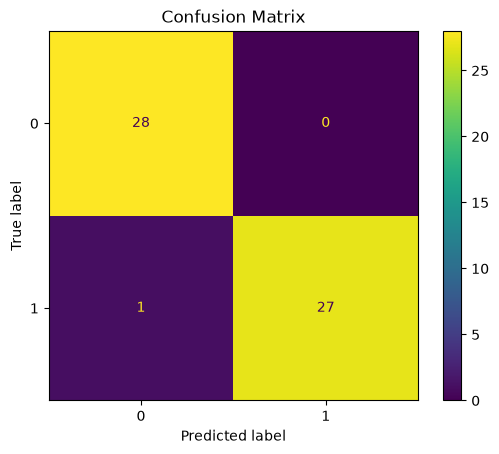

In [4]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions)
plt.title('Confusion Matrix')
plt.show()

### Averaging for multiple classes

Macro averaging calculates a metric per class and averages classes equally. Weighted averaging weights each class by support. Micro averaging aggregates counts across classes before calculating the metric. The choice changes how much rare classes influence the result.

In [5]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True).frame
X_reg = diabetes.drop(columns=['target'])
y_reg = diabetes['target']
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)

regressor = LinearRegression()
regressor.fit(X_train_reg, y_train_reg)
reg_predictions = regressor.predict(X_test_reg)

print('MAE:', mean_absolute_error(y_test_reg, reg_predictions))
print('RMSE:', (mean_squared_error(y_test_reg, reg_predictions) ** 0.5))
print('R2:', r2_score(y_test_reg, reg_predictions))

MAE: 42.79409467959994
RMSE: 53.85344583676592
R2: 0.4526027629719197


## Key terms and metric selection

- **Threshold:** probability cutoff that produces a class prediction.
- **Calibration:** whether predicted probabilities correspond to observed frequencies.
- **Specificity:** TN/(TN+FP), fraction of actual negatives correctly identified.
- **Support:** number of true examples in a class.

Do not select accuracy automatically for imbalanced data. Inspect precision, recall, confusion matrix and the real cost of each error.

## Try This Yourself
- Decide which metric matters most for a medical test.
- Change the classifier threshold and recalculate precision and recall.
- Compare MAE and RMSE.